# Báo cáo Bài Tập Lớn: Dự Án ChessAI - Áp Dụng DQN, Monte Carlo Tree Search Trong Huấn Luyện Mô Hình Chơi Cờ Vua

## 🧠 1. Cơ sở Toán học & Kiến trúc (Mathematical Foundation)

### A. Markov Decision Process (MDP) trong Cờ vua
Cờ vua là một trò chơi có thể được biểu diễn một cách chặt chẽ dưới dạng một **Markov Decision Process (MDP)** được định nghĩa bởi bộ 5 tham số $(S, A, P, R, \gamma)$:

1.  **Không gian trạng thái (State Space - $S$):**
    Mỗi trạng thái $s \in S$ đại diện cho cấu hình bàn cờ tại một thời điểm cụ thể (vị trí các quân cờ, lượt đi, quyền nhập thành, ô bắt tốt qua đường). Tính chất Markov được thỏa mãn vì để quyết định nước đi tối ưu tiếp theo, ta chỉ cần thông tin ở trạng thái hiện tại $s_t$ mà không cần biết lịch sử các nước đi trước đó dẫn đến thế cờ này:
    $$P(s_{t+1} \mid s_t, a_t, s_{t-1}, a_{t-1}, \dots) = P(s_{t+1} \mid s_t, a_t)$$

2.  **Không gian hành động (Action Space - $A$):**
    Tập hợp tất cả các nước đi hợp lệ $a \in A(s)$ tại trạng thái $s$. Trong ChessAI, không gian hành động được cố định hóa thành $4272$ nước đi UCI khả dĩ.

3.  **Xác suất chuyển trạng thái (Transition Probability - $P$):**
    Trong cờ vua, chuyển trạng thái là **deterministic (xác định)**. Khi người chơi thực hiện nước đi $a$ tại trạng thái $s$, bàn cờ sẽ chuyển dịch sang trạng thái duy nhất tiếp theo $s'$ với xác suất bằng $1$:
    $$P(s' \mid s, a) = 1.0$$

4.  **Hàm phần thưởng (Reward Function - $R$):**
    Phần thưởng chỉ được trả về ở cuối ván đấu (sparse reward):
    $$R(s, a) = \begin{cases} +1.0 & \text{nếu thắng (Checkmate)} \\ -1.0 & \text{nếu thua} \\ -0.9 & \text{nếu hòa (Chiến thuật "Draw = Loss" chống hòa thụ động)} \end{cases}$$

5.  **Hệ số chiết khấu (Discount Factor - $\gamma$):**
    Trong cờ vua đỉnh cao, $\gamma$ thường được đặt rất gần $1.0$ (ví dụ: $0.99$) để khuyến khích AI ưu tiên sát cục (checkmate) nhanh nhất và né tránh bị chiếu bí kéo dài.

---

### B. Thuật toán Q-Learning Sâu (Deep Q-Network - DQN)
DQN là phương pháp **Model-Free RL** (không cần mô hình chuyển trạng thái của môi trường). DQN xấp xỉ hàm giá trị hành động $Q(s, a)$ thông qua một mạng nơ-ron sâu với trọng số $\theta$:

$$Q(s, a; \theta) \approx Q^*(s, a)$$

#### Phương trình Tối ưu hóa Bellman (Bellman Optimality Equation)
Hàm $Q^*(s, a)$ tối ưu phải thỏa mãn hệ thức đệ quy:
$$Q^*(s, a) = R(s, a) + \gamma \max_{a'} Q^*(s', a')$$

#### Hàm mất mát (Loss Function) của DQN
Mạng DQN được huấn luyện bằng cách tối thiểu hóa sai số bình phương trung bình Temporal Difference (TD) sử dụng một Mạng mục tiêu (Target Network) có trọng số $\theta^-$ để ổn định hóa quá trình hội tụ:
$$\mathcal{L}(\theta) = \mathbb{E}_{(s, a, r, s') \sim \mathcal{D}} \left[ \left( r + \gamma \max_{a'} Q(s', a'; \theta^-) - Q(s, a; \theta) \right)^2 \right]$$
Trong đó $\mathcal{D}$ là **Experience Replay Buffer** lưu trữ các bộ chuyển tiếp $(s, a, r, s')$.

> [!WARNING]
> **Hạn chế của DQN trong Cờ Vua:**
> DQN gặp khó khăn cực kỳ lớn trong cờ vua vì không gian hành động quá lớn ($4272$) và luật chơi phức tạp khiến việc lấy mẫu ngẫu nhiên không hiệu quả. Do đó, các hệ thống như AlphaZero dịch chuyển sang hướng kết hợp học máy với thuật toán quy hoạch cây tìm kiếm (MCTS).

---

### C. Tìm kiếm cây Monte Carlo (Monte Carlo Tree Search - MCTS)
MCTS là thuật toán lập kế hoạch (planning) thuộc nhóm **Model-Based RL**. Trong AlphaZero/ChessAI, MCTS không hoạt động đơn độc mà được hướng dẫn bởi mạng nơ-ron hai đầu (Policy-Value Network).

MCTS hoạt động qua 4 bước lặp đi lặp lại:
1.  **Lựa chọn (Selection):** Bắt đầu từ nút gốc, duyệt xuống dưới bằng công thức **PUCT (Predictor Upper Confidence Bound applied to Trees)**:

$$a^* = \arg\max_{a} \left( Q(s, a) + C(s) \cdot P(s, a) \cdot \frac{\sqrt{N(s)}}{1 + N(s, a)} \right)$$

Với hệ số khám phá $C(s)$ được định nghĩa như sau:

$$C(s) = C_{\text{init}} + \log\left(\frac{N(s) + C_{\text{base}} + 1}{C_{\text{base}}}\right)$$

2.  **Mở rộng (Expansion):** Khi gặp nút lá, tạo các nút con cho tất cả các nước đi hợp lệ thu được từ mô hình luật của cờ vua.
3.  **Đánh giá (Evaluation):** Sử dụng mạng nơ-ron hai đầu để dự đoán xác suất nước đi kế tiếp (Prior $P(s, \cdot)$) và giá trị của thế cờ (Value $v$).
4.  **Lan truyền ngược (Backpropagation):** Cập nhật số lượt ghé thăm $N$ và giá trị trung bình $Q$ ngược lên các nút tổ tiên:

$$N(s, a) \leftarrow N(s, a) + 1, \quad W(s, a) \leftarrow W(s, a) + v, \quad Q(s, a) = \frac{W(s, a)}{N(s, a)}$$



---

## 2. Hiện thực hóa Code & Thực nghiệm (Implementation)

### PHẦN 1: THIẾT KẾ MARKOV DECISION PROCESS

#### A. Import thư viện

In [ ]:
import math
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    import chess
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "python-chess", "-q"])
    import chess


print("✅ Đã cài đặt thư viện python-chess và import các module thành công!")
print(f"Thiết bị sử dụng để chạy: {'CUDA (GPU)' if torch.cuda.is_available() else 'CPU'}")

✅ Đã cài đặt thư viện python-chess và import các module thành công!
Thiết bị sử dụng để chạy: CPU


####  B. Sinh tất cả các nước đi hợp lệ

In [ ]:
FILES = "abcdefgh"
RANKS = "12345678"
PROMOTIONS = ['q', 'r', 'n', 'b']
ALL_UCI_MOVES = []
for f1 in FILES:
    for r1 in RANKS:
        for f2 in FILES:
            for r2 in RANKS:
                ALL_UCI_MOVES.append(f"{f1}{r1}{f2}{r2}")
for f1 in FILES:
    for f2 in FILES:
        if abs(FILES.index(f1) - FILES.index(f2)) <= 1:
            for p in PROMOTIONS:
                ALL_UCI_MOVES.append(f"{f1}7{f2}8{p}")
                ALL_UCI_MOVES.append(f"{f1}2{f2}1{p}")
ALL_UCI_MOVES = sorted(list(set(ALL_UCI_MOVES)))
MOVE_TO_INDEX = {move: i for i, move in enumerate(ALL_UCI_MOVES)}
INDEX_TO_MOVE = {i: move for move, i in MOVE_TO_INDEX.items()}

#### C. Thiết kế môi trường bàn cờ

In [ ]:
class ChessMDP:
    """
    Đóng gói môi trường Cờ Vua dưới dạng Markov Decision Process (MDP).
    """
    def __init__(self, fen=None):
        # Trạng thái ban đầu s_0
        self.board = chess.Board(fen) if fen else chess.Board()
        self.gamma = 0.99 # Hệ số chiết khấu

    def get_state(self) -> np.ndarray:
        """
        Mã hóa Trạng thái bàn cờ (State s) thành Tensor 18 kênh (18, 8, 8) phục vụ Deep Learning.
        - Kênh 0-5: Quân Trắng (Tốt, Mã, Tượng, Xe, Hậu, Vua)
        - Kênh 6-11: Quân Đen
        - Kênh 12: Lượt đi (1.0 nếu Trắng đi, 0.0 nếu Đen đi)
        - Kênh 13-16: Quyền nhập thành (Kingside/Queenside của Trắng và Đen)
        - Kênh 17: Vị trí ô bắt tốt qua đường (En-passant)
        """
        tensor = np.zeros((18, 8, 8), dtype=np.float32)
        for square in chess.SQUARES:
            piece = self.board.piece_at(square)
            if piece:
                color = int(piece.color) # 1: Trắng, 0: Đen
                piece_type = piece.piece_type - 1 # 0 đến 5
                channel = piece_type if color == 1 else piece_type + 6
                rank, file = chess.square_rank(square), chess.square_file(square)
                tensor[channel, rank, file] = 1.0

        # Lượt đi
        if self.board.turn == chess.WHITE:
            tensor[12, :, :] = 1.0

        # Quyền nhập thành
        if self.board.has_kingside_castling_rights(chess.WHITE): tensor[13, :, :] = 1.0
        if self.board.has_queenside_castling_rights(chess.WHITE): tensor[14, :, :] = 1.0
        if self.board.has_kingside_castling_rights(chess.BLACK): tensor[15, :, :] = 1.0
        if self.board.has_queenside_castling_rights(chess.BLACK): tensor[16, :, :] = 1.0

        # Bắt tốt qua đường (En-passant)
        if self.board.ep_square is not None:
            rank, file = chess.square_rank(self.board.ep_square), chess.square_file(self.board.ep_square)
            tensor[17, rank, file] = 1.0

        return tensor

    def get_legal_actions(self) -> list:
        """Trả về tập hành động hợp lệ A(s) tại trạng thái hiện tại"""
        return list(self.board.legal_moves)

    def step(self, move: chess.Move) -> tuple:
        """
        Thực hiện dịch chuyển trạng thái Deterministic P(s' | s, a) = 1.0
        và trả về Phần thưởng thiết kế R(s, a).
        """
        if move not in self.board.legal_moves:
            raise ValueError(f"Nước đi {move.uci()} không hợp lệ!")

        # Thực hiện dịch chuyển trạng thái P
        self.board.push(move)
        next_state = self.get_state()
        is_done = self.board.is_game_over()

        # Tính toán phần thưởng R(s, a)
        reward = 0.0
        if is_done:
            res = self.board.result()
            if res == '1-0':
                reward = 1.0 # Trắng thắng
            elif res == '0-1':
                reward = -1.0 # Đen thắng
            elif res == '1/2-1/2':
                reward = -0.9 # Chiến thuật "Draw = Loss" trừng phạt nặng thế cờ hòa thụ động

        # Trả về bộ 4 tham số MDP chuẩn
        return next_state, reward, is_done, {}

    def render(self):
        """Hiển thị bàn cờ trực quan đồ họa SVG trên Colab"""
        display(self.board)

### PHẦN 2: THIẾT KẾ MẠNG DEEP Q-NETWORK (DQN) CHO CỜ VUA

In [ ]:
class ChessDQN(nn.Module):
    """
    Kiến trúc Deep Q-Network (DQN) xấp xỉ giá trị Q(s, a) cho Cờ Vua.
    """
    def __init__(self):
        super().__init__()
        # Trích xuất đặc trưng không gian bàn cờ bằng mạng tích chập ResNet thu nhỏ
        self.features = nn.Sequential(
            nn.Conv2d(18, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        # Fully Connected Layers ước tính Q-values cho 4272 hành động
        self.fc = nn.Sequential(
            nn.Linear(64 * 8 * 8, 512),
            nn.ReLU(),
            nn.Linear(512, 4272) # Đầu ra là 4272 giá trị Q tương ứng với 4272 nước đi UCI
        )

    def forward(self, x):
        feat = self.features(x)
        feat = feat.view(feat.size(0), -1)
        q_values = self.fc(feat)
        return q_values

    def select_action(self, state_tensor, legal_moves):
        """Lựa chọn hành động bằng cơ chế che nước đi không hợp lệ (Action Masking)"""
        with torch.no_grad():
            q_values = self.forward(state_tensor)[0].cpu().numpy()

        # Masking: Gán điểm cực âm cho các nước đi không hợp lệ
        masked_q = np.full(4272, -1e9, dtype=np.float32)
        for move in legal_moves:
            idx = MOVE_TO_INDEX.get(move.uci())
            if idx is not None:
                masked_q[idx] = q_values[idx]

        best_move_idx = np.argmax(masked_q)
        best_move_uci = INDEX_TO_MOVE[best_move_idx]
        return chess.Move.from_uci(best_move_uci), q_values[best_move_idx]

### PHẦN 3: THIẾT KẾ MẠNG HAI ĐẦU ALPHAZERO (POLICY-VALUE NETWORK)
Khác với DQN ước tính trực tiếp Q(s, a) dễ bị sụp đổ khi không gian hành động lớn, AlphaZero thiết kế một mạng Dual-Head tích hợp cơ chế Actor-Critic:
- Policy Head (Actor): Dự đoán xác suất nước đi ưu thế nhằm thu hẹp chiều rộng duyệt cây.
- Value Head (Critic): Ước tính trực giác điểm tĩnh của thế cờ [-1, 1] nhằm giới hạn chiều sâu duyệt cây.

In [ ]:
class AlphaZeroDualHeadNet(nn.Module):
    """
    Kiến trúc mạng hai đầu (Dual-Head Network) theo phong cách AlphaZero.
    """
    def __init__(self):
        super().__init__()
        self.conv_stem = nn.Sequential(
            nn.Conv2d(18, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        # Residual Block bảo toàn thông tin không gian gốc
        self.res_block = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64)
        )

        # Policy Head (Dự đoán phân phối nước đi P(s, a))
        self.policy_conv = nn.Conv2d(64, 2, kernel_size=1)
        self.policy_bn = nn.BatchNorm2d(2)
        self.policy_fc = nn.Linear(2 * 8 * 8, 4272)

        # Value Head (Dự đoán giá trị thế cờ v trong [-1, 1])
        self.value_conv = nn.Conv2d(64, 1, kernel_size=1)
        self.value_bn = nn.BatchNorm2d(1)
        self.value_fc1 = nn.Linear(1 * 8 * 8, 64)
        self.value_fc2 = nn.Linear(64, 1)

    def forward(self, x):
        feat = self.conv_stem(x)
        feat = F.relu(self.res_block(feat) + feat)

        # Policy output logits
        p_logits = self.policy_fc(F.relu(self.policy_bn(self.policy_conv(feat))).view(feat.size(0), -1))

        # Value scalar output
        v = F.relu(self.value_fc1(F.relu(self.value_bn(self.value_conv(feat))).view(feat.size(0), -1)))
        value = torch.tanh(self.value_fc2(v))

        return p_logits, value

### PHẦN 4: THUẬT TOÁN MONTE CARLO TREE SEARCH (MCTS) KẾT HỢP
- MCTS đóng vai trò là một "bộ cải tiến chính sách" (Policy Improver).

- Thuật toán sử dụng tri thức của mạng Dual-head để thực hiện tìm kiếm sâu.

In [ ]:
class MCTSNode:
    def __init__(self, prior=0.0):
        self.P = prior # Prior Probability P(s, a) nhận từ Policy Head
        self.N = 0     # Số lượt ghé thăm (Visit Count)
        self.W = 0.0   # Tổng điểm tích lũy (Total Value)
        self.Q = 0.0   # Điểm trung bình Q(s, a)
        self.children = {} # action (chess.Move) -> MCTSNode

    def expand(self, legal_moves, action_probs, board=None):
        """
        BƯỚC 2: EXPANSION (MỞ RỘNG)
        Khi gặp nút lá, tạo các nút con với Prior xác suất nhận được từ mạng nơ-ron.
        Tích hợp Heuristics Mate-in-1 để bơm điểm ưu tiên cho nước cờ kết liễu.
        """
        for move in legal_moves:
            idx = MOVE_TO_INDEX.get(move.uci(), 0)
            p = action_probs[idx]

            if board is not None:
                board.push(move)
                if board.is_checkmate():
                    p += 15.0 # Tăng vọt xác suất ưu tiên nếu đi nước này thắng luôn
                board.pop()

            self.children[move] = MCTSNode(prior=p)

    def is_leaf(self):
        return len(self.children) == 0

    def select_child(self, c_puct=1.5):
        """
        BƯỚC 1: SELECTION (LỰA CHỌN)
        Duyệt cây dựa trên công thức toán học PUCT để cân bằng Khám phá/Khai thác.
        """
        best_uct = -float('inf')
        best_child = None
        best_action = None
        sum_N = math.sqrt(self.N + 1)

        for action, child in self.children.items():
            # Công thức PUCT: Q(s, a) + U(s, a)
            u = c_puct * child.P * sum_N / (1 + child.N)
            uct = child.Q + u
            if uct > best_uct:
                best_uct = uct
                best_child = child
                best_action = action
        return best_action, best_child

    def backprop(self, value):
        """
        BƯỚC 4: BACKPROPAGATION (LAN TRUYỀN NGƯỢC)
        Cập nhật lại số lượt ghé thăm N, tổng điểm W và điểm trung bình Q.
        """
        self.N += 1
        self.W += value
        self.Q = self.W / self.N

def run_mcts_search(mdp: ChessMDP, model: nn.Module, num_simulations=100) -> chess.Move:
    """
    Quy trình tích hợp MCTS lập kế hoạch tìm nước đi tối ưu.
    """
    device = next(model.parameters()).device
    root = MCTSNode()

    # BƯỚC 3: EVALUATION (ĐÁNH GIÁ NÚT GỐC)
    state_tensor = torch.tensor(mdp.get_state()).unsqueeze(0).to(device)
    with torch.no_grad():
        logits, _ = model(state_tensor)
        probs = F.softmax(logits, dim=1)[0].cpu().numpy()
    root.expand(mdp.get_legal_actions(), probs, mdp.board)

    # Chu trình mô phỏng (Simulations)
    for _ in range(num_simulations):
        sim_board = mdp.board.copy()
        node = root
        path = [node]

        # 1. Selection (Duyệt theo PUCT)
        while not node.is_leaf():
            action, child = node.select_child()
            path.append(child)
            sim_board.push(action)
            node = child

        # 2. Evaluation & Expansion tại nút lá
        if sim_board.is_game_over():
            res = sim_board.result()
            # Reward shaping Draw = Loss
            v = -0.9 if res == '1/2-1/2' else -1.0
        else:
            # Mã hóa trạng thái tại điểm lá s'
            temp_mdp = ChessMDP()
            temp_mdp.board = sim_board.copy()
            state_t = torch.tensor(temp_mdp.get_state()).unsqueeze(0).to(device)

            with torch.no_grad():
                logits, value = model(state_t)
                probs = F.softmax(logits, dim=1)[0].cpu().numpy()
                v = value.item()
            node.expand(list(sim_board.legal_moves), probs, sim_board)

        # 3. Backpropagation (Lật ngược giá trị thế cờ theo lượt đi của hai đối thủ)
        for n in reversed(path):
            v = -v
            n.backprop(v)

    # Nước đi được chọn cuối cùng là nước đi có số lượt ghé thăm N cao nhất (Robust Action)
    best_move = max(root.children.items(), key=lambda item: item[1].N)[0]
    return best_move, root


### PHẦN 5: VÒNG LẶP ĐẤU CỜ TỰ ĐỘNG GIỮA 2 AI (SELF-PLAY GAME LOOP)

In [ ]:
import time
from IPython.display import clear_output

def play_ai_game(white_type="mcts", black_type="dqn", num_simulations=50, max_moves=50):
    """
    Vòng lặp chạy trận đấu tự động giữa 2 Agent với cấu hình tùy chọn:
    - white_type / black_type: "mcts" (AlphaZero), "dqn" (DQN), hoặc "random" (Ngẫu nhiên)
    - num_simulations: Số lượt mô phỏng MCTS (Độ sâu suy nghĩ)
    - max_moves: Số lượt nước đi giới hạn tùy chỉnh của trận đấu
    """
    env = ChessMDP()
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Khởi tạo mô hình
    dqn_net = ChessDQN().to(device)
    az_net = AlphaZeroDualHeadNet().to(device)
    dqn_net.eval()
    az_net.eval()

    move_count = 0
    print("🎬 Trận đấu bắt đầu...")
    time.sleep(1.5)

    while not env.board.is_game_over() and move_count < max_moves:
        # Xác định lượt đi
        turn = env.board.turn # True: White, False: Black
        player_name = "🔴 WHITE (Trắng)" if turn == chess.WHITE else "⚫ BLACK (Đen)"
        agent_type = white_type if turn == chess.WHITE else black_type

        # Chọn nước đi tối ưu dựa trên cấu hình Agent
        if agent_type == "mcts":
            # Sử dụng AlphaZero + MCTS
            move, root_node = run_mcts_search(env, az_net, num_simulations=num_simulations)
            info = f"MCTS (Simulations: {num_simulations}, Visits: {root_node.N}, Eval Q: {root_node.Q:.4f})"
        elif agent_type == "dqn":
            # Sử dụng DQN trực tiếp
            state_tensor = torch.tensor(env.get_state()).unsqueeze(0).to(device)
            move, q_val = dqn_net.select_action(state_tensor, env.get_legal_actions())
            info = f"DQN (Q-value: {q_val:.4f})"
        else:
            # Di chuyển ngẫu nhiên
            move = random.choice(env.get_legal_actions())
            info = "Random Moving"

        # Thực hiện nước đi trên môi trường MDP
        env.step(move)
        move_count += 1

        # Hiển thị bàn cờ động trên Colab
        clear_output(wait=True)
        print(f"============================================================")
        print(f"  NƯỚC ĐI THỨ {move_count} | LƯỢT CỦA: {player_name}")
        print(f"  Thuật toán áp dụng: {agent_type.upper()}")
        print(f"  Chi tiết tính toán: {info}")
        print(f"  Nước đi thực hiện: {move.uci()}")
        print(f"============================================================")
        env.render()

        # Kiểm tra chiếu tướng
        if env.board.is_check():
            print("⚠️ Cảnh báo: ĐANG CHIẾU TƯỚNG!")

        time.sleep(1.2) # Dừng 1.2 giây để người xem Colab kịp theo dõi nước đi

    # Kết thúc trận đấu
    clear_output(wait=True)
    print("=================== TRẬN ĐẤU KẾT THÚC ===================")
    if env.board.is_game_over():
        print(f"Kết quả chung cuộc: {env.board.result()}")
    else:
        print(f"Trận đấu dừng lại do đạt giới hạn số nước đi tùy chỉnh ({max_moves} nước).")
    env.render()

#### A. DQN vs MCTS

=================== TRẬN ĐẤU KẾT THÚC ===================
Trận đấu dừng lại do đạt giới hạn số nước đi tùy chỉnh (30 nước).


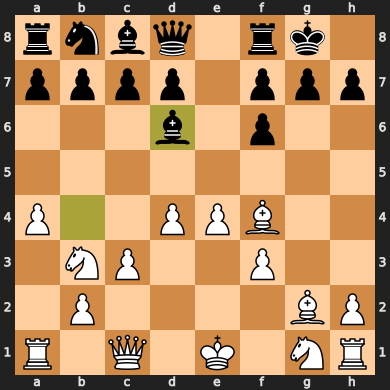

In [ ]:
play_ai_game(white_type="mcts", black_type="dqn", num_simulations=50, max_moves=30)

#### B. MCTS vs MCTS

=================== TRẬN ĐẤU KẾT THÚC ===================
Trận đấu dừng lại do đạt giới hạn số nước đi tùy chỉnh (30 nước).


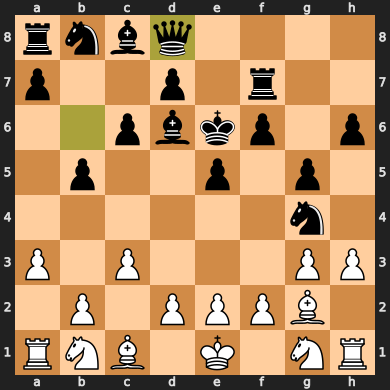

In [ ]:
play_ai_game(white_type="mcts", black_type="mcts", num_simulations=50, max_moves=30)